<a href="https://colab.research.google.com/github/Aditya03849r/DataAnalysis/blob/main/sampling.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

#import sklearn.model_selection import train_test_split

In [ ]:
#Sampling
#1. Need to Create our own DATASET
np.random.seed(42)
df=pd.DataFrame({
    'Student_ID' : range(1,101),
    'Name':[f'Student_{i}'for i in range(1,101)],
    'Gender':np.random.choice(['Male','Female'],100),
    'Department':np.random.choice(['CSE','ECE','ME','CE'],100),
    'Marks': np.random.randint(40,101,100)
})

In [ ]:
#population length
print("Population length:",len(df))

Population length: 100


In [ ]:
df.head()

,Student_ID,Name,Gender,Department,Marks
0,1,Student_1,Male,ME,71
1,2,Student_2,Female,ECE,78
2,3,Student_3,Male,ECE,88
3,4,Student_4,Male,CE,91
4,5,Student_5,Male,ECE,100


In [ ]:
#Department Value?
print(df['Department'].value_counts())
#Gender Distribution Count?
print(df['Gender'].value_counts())
#Marks Distribution Count?
print(df['Marks'].value_counts())

Department
ME     30
CSE    26
CE     24
ECE    20
Name: count, dtype: int64
Gender
Female    56
Male      44
Name: count, dtype: int64
Marks
71     7
88     6
78     5
41     5
67     5
91     4
83     4
76     4
98     3
45     3
72     3
96     3
54     2
93     2
63     2
81     2
42     2
84     2
62     2
69     2
90     2
92     2
97     2
40     2
52     2
66     2
80     2
43     1
100    1
68     1
82     1
50     1
61     1
75     1
59     1
46     1
64     1
47     1
94     1
48     1
51     1
95     1
56     1
58     1
65     1
Name: count, dtype: int64


In [ ]:
#1. Simple Random Sampling
#Every Population(student) has an equal opportunity to be selected
sample_size=10
simple_random_sample=df.sample(n=sample_size,random_state=42)
simple_random_sample

,Student_ID,Name,Gender,Department,Marks
83,84,Student_84,Female,ME,88
53,54,Student_54,Female,ME,66
70,71,Student_71,Female,CE,88
45,46,Student_46,Female,ME,96
44,45,Student_45,Female,CE,66
39,40,Student_40,Male,CSE,64
22,23,Student_23,Female,ECE,67
80,81,Student_81,Male,CSE,95
10,11,Student_11,Male,CE,78
0,1,Student_1,Male,ME,71


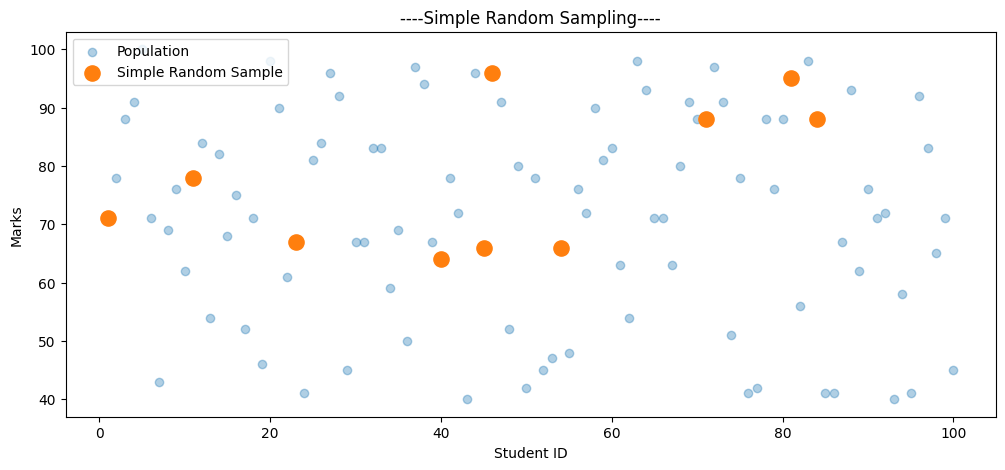

In [ ]:
#Visulisation of SRS
plt.figure(figsize=(12,5))
plt.scatter(df['Student_ID'],df['Marks'],alpha=0.35,label='Population')
plt.scatter(simple_random_sample['Student_ID'],simple_random_sample['Marks'],s=120,label='Simple Random Sample')
plt.xlabel('Student ID')
plt.ylabel('Marks')
plt.title('----Simple Random Sampling----')
plt.legend()
plt.show()

In [ ]:
#SYSTEMATIC SAMPLING:
N=len(df)
n=10
k=N//n
start=np.random.randint(0,k)
systematic_sample=df.iloc[start::k].head(n)
systematic_sample
print("Starting Position:",k)
print("\nSampling Interval:",start)
systematic_sample

Starting Position: 10

Sampling Interval: 6


,Student_ID,Name,Gender,Department,Marks
6,7,Student_7,Male,ECE,43
16,17,Student_17,Female,CSE,52
26,27,Student_27,Female,ECE,96
36,37,Student_37,Female,CSE,97
46,47,Student_47,Female,ME,91
56,57,Student_57,Female,ME,72
66,67,Student_67,Female,CE,63
76,77,Student_77,Female,ME,42
86,87,Student_87,Female,ECE,67
96,97,Student_97,Female,ECE,83


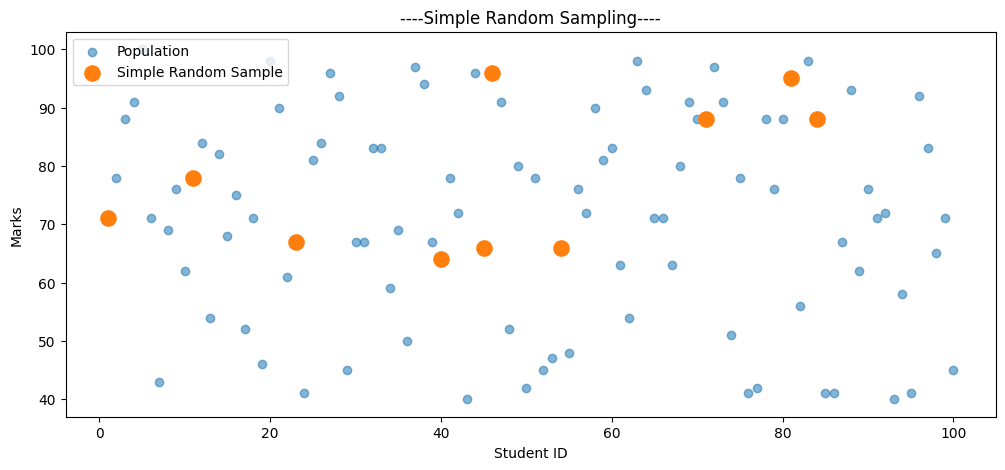

In [ ]:
#Visulisation of SRS
plt.figure(figsize=(12,5))
plt.scatter(df['Student_ID'],df['Marks'],alpha=0.55,label='Population')
plt.scatter(simple_random_sample['Student_ID'],simple_random_sample['Marks'],s=120,label='Simple Random Sample')
plt.xlabel('Student ID')
plt.ylabel('Marks')
plt.title('----Simple Random Sampling----')
plt.legend()
plt.show()

In [ ]:
from sklearn.model_selection import train_test_split

In [ ]:
#3.Stratified Sampling
sample_size=20
straitified_sample, remaining=train_test_split(
    df,
    test_size=sample_size,
    stratify=df['Department'],
    random_state=42
)
straitified_sample

,Student_ID,Name,Gender,Department,Marks
65,66,Student_66,Female,CSE,71
6,7,Student_7,Male,ECE,43
86,87,Student_87,Female,ECE,67
56,57,Student_57,Female,ME,72
96,97,Student_97,Female,ECE,83
...,...,...,...,...,...
40,41,Student_41,Male,CE,78
32,33,Student_33,Female,CSE,83
67,68,Student_68,Male,ME,80
27,28,Student_28,Female,CSE,92


In [ ]:
print("Original Department Propotions:")
print(df['Department'].value_counts(normalize=True).round(2))
print("\n Sample Distribution Propotion:")
print(straitified_sample['Department'].value_counts(normalize=True).round(2))

Original Department Propotions:
Department
ME     0.30
CSE    0.26
CE     0.24
ECE    0.20
Name: proportion, dtype: float64

 Sample Distribution Propotion:
Department
ME     0.30
CSE    0.26
CE     0.24
ECE    0.20
Name: proportion, dtype: float64


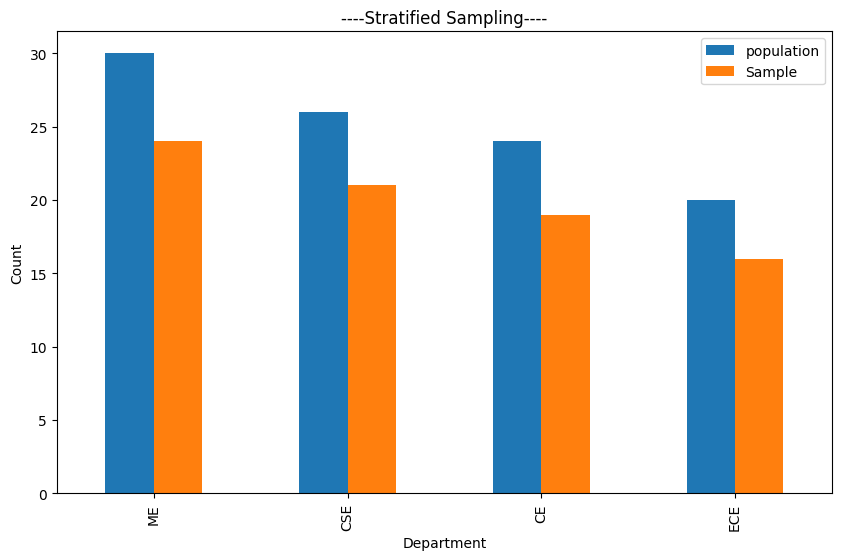

In [ ]:
#Visulization of Startified Sampling
comparison=pd.DataFrame({
    'population':df['Department'].value_counts(),
    'Sample':straitified_sample['Department'].value_counts()
})
comparison.plot(kind='bar',figsize=(10,6))
plt.xlabel('Department')
plt.ylabel('Count')
plt.title('----Stratified Sampling----')
plt.show()
